# Analysing RNTuple CAFs with Python with uproot and awkward

## Import modules etc.

In [1]:
!pip install uproot matplotlib awkward mplhep


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import uproot
import matplotlib.pyplot as plt
import awkward as ak
import mplhep

In [3]:
mplhep.style.use("CMS")
plt.rcParams["figure.figsize"] = (7, 6)

## Open CAF and have an explore

In [4]:
caf = uproot.open("../build/example_spills.root")["CAF"].arrays()

In [5]:
caf.fields

['common', 'mc']

### Write function to calculate track lengths

In [6]:
def get_lengths(part):
  dx = part.end.fCoordinates.fX - part.start.fCoordinates.fX 
  dy = part.end.fCoordinates.fY - part.start.fCoordinates.fY 
  dz = part.end.fCoordinates.fZ - part.start.fCoordinates.fZ 
  return (dx**2 + dy**2 + dz**2)**0.5

In [7]:
lengths = get_lengths(caf.common.dlp.part)

In [8]:
lengths

<Array [[[73.6, 335, 222, 277], ...], ...] type='13 * var * var * float64'>

In [9]:
lengths[0] # first spill

<Array [[73.6, 335, 222, 277], ..., [25.6, ..., 337]] type='47 * var * float64'>

In [10]:
lengths[0][0] # first interaction of first spill

<Array [73.6, 335, 222, 277] type='4 * float64'>

In [11]:
lengths[0][0][0] # first particle of first interaction of first spill

np.float64(73.619631447052)

In [12]:
ak.flatten(lengths, axis=None) # flattened across spills and interactions

<Array [73.6, 335, 222, 277, ..., 80.5, 318, 21.8, 127] type='2272 * float64'>

## Plot all track lengths

In [13]:
def plot(feature, label):
  plt.hist(ak.flatten(feature, axis=None), bins=50)
  plt.xlabel(label)
  plt.ylabel("Frequency")
  plt.show()

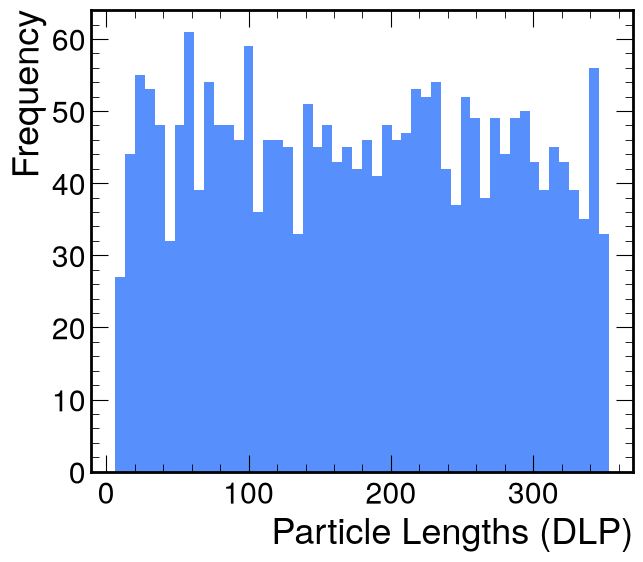

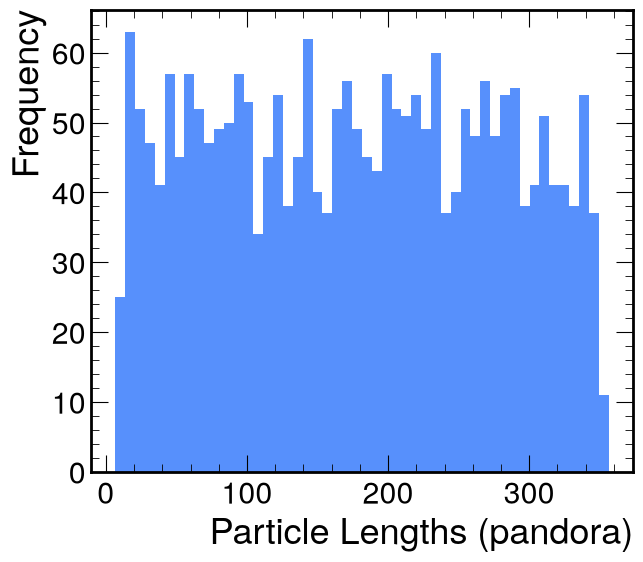

In [14]:
plot(get_lengths(caf.common.dlp.part), "Particle Lengths (DLP)")
plot(get_lengths(caf.common.pandora.part), "Particle Lengths (pandora)")

## Plot all neutrino energies (interaction level)

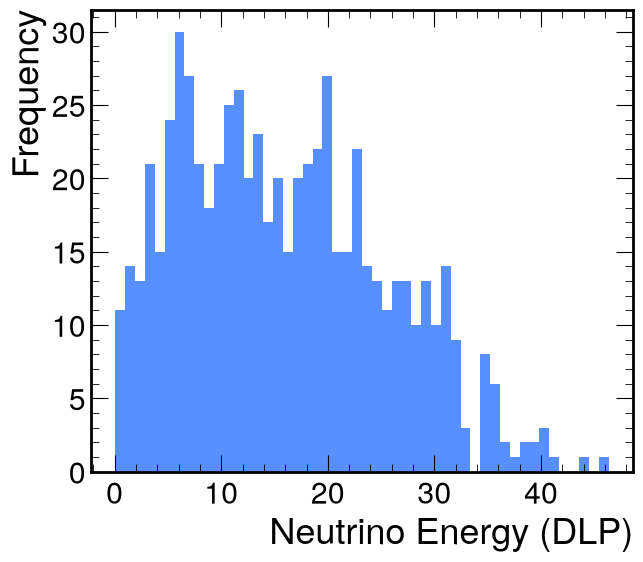

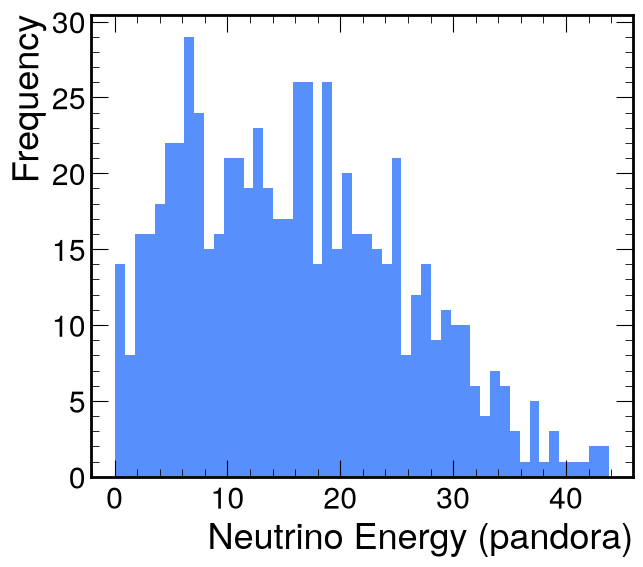

In [15]:
plot(caf.common.dlp.Enu, "Neutrino Energy (DLP)")
plot(caf.common.pandora.Enu, "Neutrino Energy (pandora)")

## Muon resolution plot

In this example, we just want the resolution of all muons across all spills and interactions, so to make our life a bit easier, we can drop the spill and interaction structure by flattening the arrays.

In [16]:
ixns = ak.flatten(caf.common.dlp) # flatten across spills
parts = ak.flatten(ixns.part) # flatten across interactions

In [17]:
parts

<Array [{id: 0, primary: True, ...}, ...] type='2272 * {id: uint64, primary...'>

In [18]:
is_muon = abs(parts.pdg) == 13
has_truth_match = ak.count(parts.truth, axis=-1) > 0
reco_muons = parts[is_muon & has_truth_match]

In [19]:
truth_ixns = ak.flatten(caf.mc.interactions)
true_parts = ak.flatten(truth_ixns.part)

In [20]:
reco_muons

<Array [{id: 0, primary: True, ...}, ...] type='522 * {id: uint64, primary:...'>

In [21]:
true_muon_idx = reco_muons.truth[:, 0] # assuming ordered by truthOverlap
true_muons = true_parts[true_muon_idx]

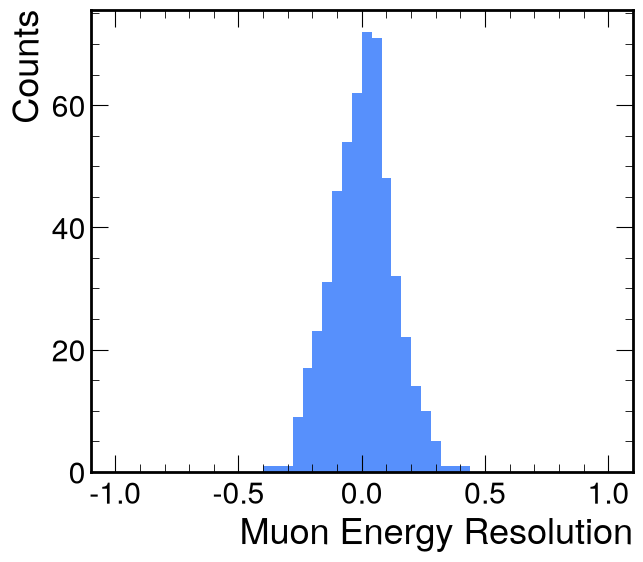

In [22]:
resolution = (reco_muons.E - true_muons.E) / true_muons.E

plt.hist(resolution, bins=50, range=(-1, 1))
plt.xlabel("Muon Energy Resolution")
plt.ylabel("Counts")
plt.show("muon_energy_resolution.png")

## Applying a selection

In this example, we assert that neutrino energy (interaction) level is greater than 2 GeV. And that an interaction must have at least one primary, and that all primaries must be contained.

In [23]:
def passes_selection(ixn):
  enu_cut = ixn.Enu > 2
  has_primary = ak.any(ixn.part.primary, axis=-1)
  all_primary_contained = ak.all(ixn.part.contained | ~ixn.part.primary, axis=-1)

  return enu_cut & has_primary & all_primary_contained

In [24]:
ixns = ak.flatten(caf.common.dlp)
selection_mask = passes_selection(ixns)

efficiency = ak.sum(selection_mask) / len(selection_mask)
print(f"Selection efficiency: {efficiency:.4f}")

Selection efficiency: 0.3752
